# Notebook 03 — Base Model Benchmark
## FYP: Adaptive Explainable Ensemble for Pre-Launch Steam Game Reception Prediction
### Heshan Ratnaweera | IIT Sri Lanka | W2082289 | 2026

**Purpose:** Benchmark four classifiers (Logistic Regression, Random Forest, XGBoost, CatBoost)
on the full T4 feature set to establish a baseline and select the best classifier
for training specialist Models A–D in notebook 04.

**Inputs:** `data/processed/games_features_t4.csv`
**Outputs:** `outputs/results/benchmark_table.csv`
**Key results:** *(fill in after running)*

> **Revision note (v2):** Fixed two bugs.
> 1. **`is_winner` matching bug** — Section 9 built `benchmark_table.csv` by checking
>    `name == WINNER_NAME`, but when a *tuned* model wins, `WINNER_NAME` holds a label
>    like `"CB tuned"` which never equals any of the four baseline names in `cv_results`
>    (`"Logistic Regression"`, `"Random Forest"`, `"XGBoost"`, `"CatBoost"`). Every row's
>    `is_winner` silently came out `False`, and every `test_*` column was saved as `None`
>    — the actual winning model's test performance was never recorded in the table. Fixed
>    with an explicit label→classifier-name mapping (`WINNER_BASE_NAME`).
> 2. **Threshold tuned on the test set** — Section 8 swept decision thresholds against
>    `y_test`/`y_prob` (computed from the held-out test set) to pick `BEST_THRESHOLD`,
>    then reported "optimal" test performance using that same threshold on that same
>    test set. That's the test set being used twice — once to choose the threshold,
>    once to report performance under it — which inflates the "optimal" numbers. Fixed
>    to tune the threshold using cross-validated (out-of-fold) predictions on the
>    **training set only**, then apply that frozen threshold to the test set exactly once.

> **Revision note (v4):** Section 6b's `RandomizedSearchCV` tried 30 hyperparameter
> combinations per classifier but only ever surfaced the single winner — the other 29
> trials were computed by sklearn and then discarded, so the depth/learning_rate/l2
> choice couldn't actually be verified, just trusted. Now exports **all** trials (both
> RF and CatBoost) to `03_hyperparameter_search_trials.csv`, ranked by CV Macro F1, so
> the full comparison is retained and auditable — not just the winning row.

---
## Contents
1. Setup & Imports
2. Load Dataset
3. Train-Test Split
4. Define Classifiers
5. Cross-Validation Benchmark
6. Class Imbalance Strategy Comparison
6b. Hyperparameter Tuning
7. Results Visualisation
8. Winner Selection
9. Save Benchmark Table
10. Summary


## 1. Setup & Imports

In [1]:
import sys
import warnings
import time
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# ── Machine learning ───────────────────────────────────────────────────────────
from sklearn.linear_model    import LogisticRegression
from sklearn.ensemble        import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.metrics         import (f1_score, roc_auc_score, precision_score,
                                     recall_score, confusion_matrix, accuracy_score,
                                     ConfusionMatrixDisplay, classification_report)
from sklearn.preprocessing   import StandardScaler
from sklearn.pipeline        import Pipeline

from xgboost  import XGBClassifier
from catboost import CatBoostClassifier

# SMOTE for class imbalance handling
try:
    from imblearn.over_sampling import SMOTE
    from imblearn.pipeline      import Pipeline as ImbPipeline
    SMOTE_AVAILABLE = True
except ImportError:
    print('imbalanced-learn not installed — SMOTE comparison will be skipped')
    print('Install with: pip install imbalanced-learn')
    SMOTE_AVAILABLE = False

warnings.filterwarnings('ignore')
pd.set_option('display.float_format', '{:.4f}'.format)
sns.set_theme(style='darkgrid', palette='muted')

# ── Add project root to path ───────────────────────────────────────────────────
PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))

from src.config import (
    FEATURES_T4_CSV, RESULTS_DIR, FIGURES_DIR,
    TARGET_COL, RANDOM_STATE, CV_FOLDS,
    TIER1_FEATURES, TIER2_FEATURES, TIER3_FEATURES
)

RESULTS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print('All imports OK')
print(f'Project root : {PROJECT_ROOT}')
print(f'Input CSV    : {FEATURES_T4_CSV}')


All imports OK
Project root : C:\Users\3214h\Documents\fyp-steam-reception
Input CSV    : C:\Users\3214h\Documents\fyp-steam-reception\data\processed\games_features_t4.csv


## 2. Load Dataset

Load `games_features_t4.csv` produced by notebook 02.
`short_description` is excluded from features here, it is used only in notebook 05 (SBERT).
`dlc_count` is also excluded from model features, it feeds `price_to_dlc_ratio` but is
not used as a standalone feature (r=0.005, not significant).


In [2]:
# ── Load the processed feature matrix ─────────────────────────────────────────
assert FEATURES_T4_CSV.exists(), f'File not found: {FEATURES_T4_CSV}. Run notebook 02 first.'

df = pd.read_csv(FEATURES_T4_CSV)
print(f'Loaded: {df.shape[0]:,} rows × {df.shape[1]} columns')
print(f'Class balance: {df[TARGET_COL].mean():.3f} positive ({df[TARGET_COL].mean()*100:.1f}%)')

# ── Define the full T4 feature set ────────────────────────────────────────────
# Exclude:
#   TARGET_COL        → this is what we are predicting (y)
#   short_description → text source for SBERT in notebook 05, not a numeric feature
#   dlc_count         → not used as standalone feature (only feeds price_to_dlc_ratio)
EXCLUDE_COLS = [TARGET_COL, 'short_description', 'dlc_count']

T4_FEATURES = [c for c in df.columns if c not in EXCLUDE_COLS]

print(f'\nT4 feature columns ({len(T4_FEATURES)} total):')
for i, col in enumerate(T4_FEATURES):
    print(f'  {i+1:>2}. {col}')


Loaded: 20,383 rows × 55 columns
Class balance: 0.718 positive (71.8%)

T4 feature columns (53 total):
   1. price
   2. required_age
   3. is_free
   4. price_to_dlc_ratio
   5. platform_coverage
   6. has_achievements
   7. has_website
   8. genre_concentration
   9. supported_languages_count
  10. screenshot_count
  11. movie_count
  12. genre_Indie
  13. genre_Adventure
  14. genre_Action
  15. genre_Casual
  16. genre_Simulation
  17. genre_RPG
  18. genre_Strategy
  19. genre_Free_To_Play
  20. genre_Early_Access
  21. genre_Massively_Multiplayer
  22. tag_Singleplayer
  23. tag_Indie
  24. tag_Adventure
  25. tag_Action
  26. tag_Casual
  27. tag_2D
  28. tag_Simulation
  29. tag_RPG
  30. tag_Atmospheric
  31. tag_Story_Rich
  32. tag_Strategy
  33. tag_Multiplayer
  34. tag_Puzzle
  35. tag_Exploration
  36. tag_First_Person
  37. tag_Anime
  38. tag_Funny
  39. tag_3D
  40. tag_Cute
  41. tag_Fantasy
  42. cat_Single_player
  43. cat_Multi_player
  44. cat_Co_op
  45. cat_Ste

## 3. Train-Test Split

80% train / 20% test, stratified by label to preserve the 71.8% / 28.2% class ratio.
The test set is held out completely — it is only used in section 8 for final evaluation
of the winning model. Cross-validation in sections 5 and 6 uses only the train set.

`RANDOM_STATE = 42` ensures reproducibility across all runs.


In [3]:
# ── Prepare feature matrix X and label vector y ───────────────────────────────
X = df[T4_FEATURES].values   # numpy array — faster for sklearn
y = df[TARGET_COL].values

print(f'X shape: {X.shape}')
print(f'y shape: {y.shape}')
print(f'Positive class (label=1): {y.sum():,} ({y.mean()*100:.1f}%)')
print(f'Negative class (label=0): {(1-y).sum():,} ({(1-y).mean()*100:.1f}%)')

# ── Stratified train-test split ────────────────────────────────────────────────
# stratify=y ensures both splits have the same class ratio as the full dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y      # preserves 71.8% / 28.2% ratio in both splits
)

print(f'\nTrain set : {X_train.shape[0]:,} games  '
      f'(positive: {y_train.mean()*100:.1f}%)')
print(f'Test set  : {X_test.shape[0]:,} games  '
      f'(positive: {y_test.mean()*100:.1f}%)')
print(f'\nTest set is held out until section 8 — not used during cross-validation')


X shape: (20383, 53)
y shape: (20383,)
Positive class (label=1): 14,631 (71.8%)
Negative class (label=0): 5,752 (28.2%)

Train set : 16,306 games  (positive: 71.8%)
Test set  : 4,077 games  (positive: 71.8%)

Test set is held out until section 8 — not used during cross-validation


## 4. Define Classifiers

Four classifiers are benchmarked:

**Logistic Regression** — linear baseline. Requires feature scaling (StandardScaler).
Tells us whether the problem has a linear solution.

**Random Forest** — ensemble of decision trees. No scaling needed. Good baseline
for tree-based methods.

**XGBoost** — gradient boosting. Generally strong on tabular data. Fast training.

**CatBoost** — gradient boosting designed for categorical features. Handles class
imbalance well via `scale_pos_weight`. Often the strongest performer on mixed
tabular datasets.

The winner from this benchmark becomes the classifier for Models A–D in notebook 04.


In [4]:
# ── Class imbalance weight ────────────────────────────────────────────────────
# Goal: treat both classes equally → PRIMARY METRIC is macro F1.
# All four classifiers must use equivalent imbalance handling for a fair comparison.
# sklearn classifiers: class_weight='balanced'
# XGBoost / CatBoost: scale_pos_weight = neg_count / pos_count (same effect)
neg_count = (y_train == 0).sum()
pos_count = (y_train == 1).sum()
scale_pos_weight = neg_count / pos_count

print(f'Training set class distribution:')
print(f'  Not Well Received (label=0): {neg_count:,}  ({neg_count/len(y_train)*100:.1f}%)')
print(f'  Well Received     (label=1): {pos_count:,}  ({pos_count/len(y_train)*100:.1f}%)')
print(f'  scale_pos_weight           : {scale_pos_weight:.4f}')
print(f'\nAll classifiers configured with equivalent class imbalance handling.')

CLASSIFIERS = {

    'Logistic Regression': Pipeline([
        ('scaler', StandardScaler()),
        ('clf', LogisticRegression(
            class_weight='balanced',
            max_iter=1000,
            random_state=RANDOM_STATE,
            n_jobs=-1
        ))
    ]),

    'Random Forest': RandomForestClassifier(
        n_estimators=300,
        class_weight='balanced',   # upweights minority class proportionally
        max_depth=None,
        min_samples_leaf=2,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ),

    'XGBoost': XGBClassifier(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=6,
        scale_pos_weight=scale_pos_weight,  # equivalent to class_weight='balanced'
        eval_metric='logloss',
        use_label_encoder=False,
        random_state=RANDOM_STATE,
        n_jobs=-1,
        verbosity=0
    ),

    'CatBoost': CatBoostClassifier(
        iterations=300,
        learning_rate=0.05,
        depth=6,
        scale_pos_weight=scale_pos_weight,  # equivalent to class_weight='balanced'
        random_seed=RANDOM_STATE,
        verbose=0
    ),
}

print(f'\n{len(CLASSIFIERS)} classifiers defined:')
for name in CLASSIFIERS:
    print(f'  - {name}')


Training set class distribution:
  Not Well Received (label=0): 4,601  (28.2%)
  Well Received     (label=1): 11,705  (71.8%)
  scale_pos_weight           : 0.3931

All classifiers configured with equivalent class imbalance handling.

4 classifiers defined:
  - Logistic Regression
  - Random Forest
  - XGBoost
  - CatBoost


## 5. Cross-Validation Benchmark

5-fold stratified cross-validation on the **training set only**.
The test set remains untouched.

Metrics recorded for each fold:
- **Macro F1** — primary metric. Averages F1 equally across both classes regardless of class size
- **F1 (minority class)** — F1 score specifically for the "Not Well Received" class (label=0)
- **Accuracy** — percentage of games correctly classified across both classes
- **AUC-ROC** — overall discriminative ability across all thresholds
- **Precision** — of games predicted "not well received", how many actually are?
- **Recall** — of games that are "not well received", how many did we catch?

Macro F1 is the primary metric rather than accuracy because 71.8% of games in the dataset
are Well Received. A model that always predicts "Well Received" would score 71.8% accuracy
without learning anything useful. Accuracy is still recorded here for completeness and
to provide a familiar reference point alongside the other metrics.


In [5]:
from sklearn.metrics import make_scorer

# Scorers for each class specifically
# pos_label=0 → F1 for the minority class (Not Well Received)
# pos_label=1 → F1 for the majority class (Well Received)
f1_minority_scorer = make_scorer(f1_score, pos_label=0)
f1_majority_scorer = make_scorer(f1_score, pos_label=1)

# PRIMARY METRIC: macro F1 = (F1_minority + F1_majority) / 2
# Equal weight to both classes — aligns with project goal of helping developers
# identify both successes and games at risk of poor reception.
cv = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)
cv_results = {}

print(f'Running {CV_FOLDS}-fold stratified CV on training set ({X_train.shape[0]:,} games)...')
print(f'PRIMARY METRIC: Macro F1 (equal weight to both classes)')
print()

for name, clf in CLASSIFIERS.items():
    print(f'Training {name}...', end=' ', flush=True)
    start = time.time()

    scores = cross_validate(
        clf, X_train, y_train,
        cv=cv,
        scoring={
            'f1_macro':    'f1_macro',         # PRIMARY — equal weight both classes
            'f1_minority': f1_minority_scorer,  # F1 for Not Well Received (label=0)
            'f1_majority': f1_majority_scorer,  # F1 for Well Received (label=1)
            'roc_auc':     'roc_auc',
            'precision':   'precision_macro',
            'recall':      'recall_macro',
            'accuracy':    'accuracy',           # NEW — raw accuracy across both classes
        },
        n_jobs=1,
        return_train_score=False
    )

    elapsed = time.time() - start

    cv_results[name] = {
        'f1_macro_mean':    scores['test_f1_macro'].mean(),
        'f1_macro_std':     scores['test_f1_macro'].std(),
        'f1_minority_mean': scores['test_f1_minority'].mean(),
        'f1_minority_std':  scores['test_f1_minority'].std(),
        'f1_majority_mean': scores['test_f1_majority'].mean(),
        'f1_majority_std':  scores['test_f1_majority'].std(),
        'auc_mean':         scores['test_roc_auc'].mean(),
        'auc_std':          scores['test_roc_auc'].std(),
        'precision_mean':   scores['test_precision'].mean(),
        'recall_mean':      scores['test_recall'].mean(),
        'time_sec':         elapsed,
        'fold_macro_f1s':   scores['test_f1_macro'].tolist(),
        'fold_minor_f1s':   scores['test_f1_minority'].tolist(),
        'accuracy_mean':     scores['test_accuracy'].mean(),
        'accuracy_std':      scores['test_accuracy'].std(),
    }

    print(f'done in {elapsed:.1f}s  |  '
          f'Macro F1={scores["test_f1_macro"].mean():.4f} ± {scores["test_f1_macro"].std():.4f}  |  '
          f'Minority F1={scores["test_f1_minority"].mean():.4f}  |  '
          f'AUC={scores["test_roc_auc"].mean():.4f}  |  '
          f'Accuracy={scores["test_accuracy"].mean():.4f}')

print()
results_df = pd.DataFrame({
    name: {
        'Macro F1 (mean)':    f'{r["f1_macro_mean"]:.4f}',
        'Macro F1 (± std)':   f'{r["f1_macro_std"]:.4f}',
        'Minority F1 (mean)': f'{r["f1_minority_mean"]:.4f}',
        'Majority F1 (mean)': f'{r["f1_majority_mean"]:.4f}',
        'AUC-ROC (mean)':     f'{r["auc_mean"]:.4f}',
        'AUC-ROC (± std)':    f'{r["auc_std"]:.4f}',
        'Macro Precision':    f'{r["precision_mean"]:.4f}',
        'Macro Recall':       f'{r["recall_mean"]:.4f}',
        'Accuracy (mean)':    f'{r["accuracy_mean"]:.4f}',
        'Train time (s)':     f'{r["time_sec"]:.1f}',
    }
    for name, r in cv_results.items()
}).T

print('=== 5-FOLD CV RESULTS — PRIMARY METRIC: MACRO F1 ===')
print(results_df.to_string())
print()
print('Minority F1 = F1 for Not Well Received (label=0) — detecting games at risk')
print('Majority F1 = F1 for Well Received     (label=1)')


Running 5-fold stratified CV on training set (16,306 games)...
PRIMARY METRIC: Macro F1 (equal weight to both classes)

Training Logistic Regression... done in 0.4s  |  Macro F1=0.6311 ± 0.0040  |  Minority F1=0.5218  |  AUC=0.7158  |  Accuracy=0.6635
Training Random Forest... done in 8.8s  |  Macro F1=0.6677 ± 0.0086  |  Minority F1=0.5243  |  AUC=0.7444  |  Accuracy=0.7296
Training XGBoost... done in 2.5s  |  Macro F1=0.6591 ± 0.0072  |  Minority F1=0.5390  |  AUC=0.7379  |  Accuracy=0.7014
Training CatBoost... done in 11.4s  |  Macro F1=0.6580 ± 0.0019  |  Minority F1=0.5438  |  AUC=0.7443  |  Accuracy=0.6961

=== 5-FOLD CV RESULTS — PRIMARY METRIC: MACRO F1 ===
                    Macro F1 (mean) Macro F1 (± std) Minority F1 (mean) Majority F1 (mean) AUC-ROC (mean) AUC-ROC (± std) Macro Precision Macro Recall Accuracy (mean) Train time (s)
Logistic Regression          0.6311           0.0040             0.5218             0.7404         0.7158          0.0079          0.6326       

## 6. Class Imbalance Strategy Comparison

Three strategies for handling the 71.8% / 28.2% class imbalance:

**No resampling** — train on the raw imbalanced data, rely on class_weight parameter

**class_weight='balanced'** — already used in section 5; sklearn automatically
adjusts sample weights so the minority class has equal total weight

**SMOTE** — Synthetic Minority Over-sampling Technique. Creates synthetic examples
of the minority class by interpolating between existing minority samples.
Applied only to the training fold, never to the validation fold (no leakage).

We test these three strategies on the best classifier from section 5.


In [6]:
# ── Select best classifier by MACRO F1 ────────────────────────────────────────
best_name = max(cv_results, key=lambda k: cv_results[k]['f1_macro_mean'])
print(f'Best classifier by Macro F1: {best_name}')
print(f'  Macro F1    = {cv_results[best_name]["f1_macro_mean"]:.4f} ± {cv_results[best_name]["f1_macro_std"]:.4f}')
print(f'  Minority F1 = {cv_results[best_name]["f1_minority_mean"]:.4f}')
print(f'  Majority F1 = {cv_results[best_name]["f1_majority_mean"]:.4f}')
print()

# ── Compare three imbalance strategies — all measured by MACRO F1 ─────────────
imbalance_results = {}

# Strategy 1: class_weight (already in section 5)
print('Strategy 1: class_weight="balanced" / scale_pos_weight (already in section 5)...')
imbalance_results['class_weight'] = {
    'f1_macro_mean':    cv_results[best_name]['f1_macro_mean'],
    'f1_macro_std':     cv_results[best_name]['f1_macro_std'],
    'f1_minority_mean': cv_results[best_name]['f1_minority_mean'],
    'auc_mean':         cv_results[best_name]['auc_mean'],
}
print(f'  Macro F1={imbalance_results["class_weight"]["f1_macro_mean"]:.4f}  '
      f'Minority F1={imbalance_results["class_weight"]["f1_minority_mean"]:.4f}')

# Strategy 2: No class weighting
print('Strategy 2: No class weighting...')
if best_name == 'CatBoost':
    clf_nw = CatBoostClassifier(iterations=300, learning_rate=0.05, depth=6,
                                 random_seed=RANDOM_STATE, verbose=0)
elif best_name == 'XGBoost':
    clf_nw = XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=6,
                            eval_metric='logloss', use_label_encoder=False,
                            random_state=RANDOM_STATE, n_jobs=-1, verbosity=0)
elif best_name == 'Random Forest':
    clf_nw = RandomForestClassifier(n_estimators=300, max_depth=None,
                                    min_samples_leaf=2, random_state=RANDOM_STATE, n_jobs=-1)
else:
    clf_nw = Pipeline([('scaler', StandardScaler()),
                       ('clf', LogisticRegression(max_iter=1000,
                                                  random_state=RANDOM_STATE, n_jobs=-1))])

s_nw = cross_validate(clf_nw, X_train, y_train, cv=cv,
                      scoring={'f1_macro': 'f1_macro',
                               'f1_minority': f1_minority_scorer,
                               'roc_auc': 'roc_auc'}, n_jobs=1)
imbalance_results['no_weighting'] = {
    'f1_macro_mean':    s_nw['test_f1_macro'].mean(),
    'f1_macro_std':     s_nw['test_f1_macro'].std(),
    'f1_minority_mean': s_nw['test_f1_minority'].mean(),
    'auc_mean':         s_nw['test_roc_auc'].mean(),
}
print(f'  Macro F1={imbalance_results["no_weighting"]["f1_macro_mean"]:.4f}  '
      f'Minority F1={imbalance_results["no_weighting"]["f1_minority_mean"]:.4f}')

# Strategy 3: SMOTE
if SMOTE_AVAILABLE:
    print('Strategy 3: SMOTE...')
    smote_clf = ImbPipeline([('smote', SMOTE(random_state=RANDOM_STATE)),
                              ('clf', CLASSIFIERS[best_name])])
    s_sm = cross_validate(smote_clf, X_train, y_train, cv=cv,
                          scoring={'f1_macro': 'f1_macro',
                                   'f1_minority': f1_minority_scorer,
                                   'roc_auc': 'roc_auc'}, n_jobs=1)
    imbalance_results['SMOTE'] = {
        'f1_macro_mean':    s_sm['test_f1_macro'].mean(),
        'f1_macro_std':     s_sm['test_f1_macro'].std(),
        'f1_minority_mean': s_sm['test_f1_minority'].mean(),
        'auc_mean':         s_sm['test_roc_auc'].mean(),
    }
    print(f'  Macro F1={imbalance_results["SMOTE"]["f1_macro_mean"]:.4f}  '
          f'Minority F1={imbalance_results["SMOTE"]["f1_minority_mean"]:.4f}')
else:
    print('Strategy 3: SMOTE skipped — install imbalanced-learn to enable')

print()
print(f'=== IMBALANCE STRATEGY COMPARISON ({best_name}) — ranked by Macro F1 ===')
print(f'  {"Strategy":<20} {"Macro F1":>10} {"Minority F1":>12} {"AUC":>8}')
print('  ' + '-' * 54)
for strat, r in sorted(imbalance_results.items(),
                        key=lambda x: x[1]['f1_macro_mean'], reverse=True):
    print(f'  {strat:<20} {r["f1_macro_mean"]:>10.4f} {r["f1_minority_mean"]:>12.4f} {r["auc_mean"]:>8.4f}')

best_strategy = max(imbalance_results, key=lambda k: imbalance_results[k]['f1_macro_mean'])
print(f'\n  Best strategy (by Macro F1): {best_strategy}')


Best classifier by Macro F1: Random Forest
  Macro F1    = 0.6677 ± 0.0086
  Minority F1 = 0.5243
  Majority F1 = 0.8111

Strategy 1: class_weight="balanced" / scale_pos_weight (already in section 5)...
  Macro F1=0.6677  Minority F1=0.5243
Strategy 2: No class weighting...
  Macro F1=0.6043  Minority F1=0.3617
Strategy 3: SMOTE...
  Macro F1=0.6205  Minority F1=0.3973

=== IMBALANCE STRATEGY COMPARISON (Random Forest) — ranked by Macro F1 ===
  Strategy               Macro F1  Minority F1      AUC
  ------------------------------------------------------
  class_weight             0.6677       0.5243   0.7444
  SMOTE                    0.6205       0.3973   0.7419
  no_weighting             0.6043       0.3617   0.7422

  Best strategy (by Macro F1): class_weight


## 6b. Hyperparameter Tuning — Improve Macro F1

The baseline benchmark used default hyperparameters. This section tunes the
top two classifiers to squeeze more performance from the current feature set.

**Two tuning strategies:**
1. **Weight ratio search** — test custom class weight ratios beyond `balanced`.
   Higher minority weight forces the model to focus more on Not Well Received games.
2. **RandomizedSearchCV** — random search over key hyperparameters using macro F1
   as the optimisation target.

Expected ceiling with current 53 structured features: macro F1 ≈ 0.70–0.72.
Further improvement beyond that requires the SBERT text features in notebook 05.


In [7]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint, uniform

# ── Strategy 1: Weight ratio search ───────────────────────────────────────────
# class_weight='balanced' gives minority weight of 0.39 automatically.
# We test higher ratios to see if pushing harder on the minority class helps.
# Format: {0: minority_weight, 1: 1} — label 0 is Not Well Received
print('=== WEIGHT RATIO SEARCH ===')
print('Testing custom weight ratios on Random Forest and CatBoost...')
print()

weight_ratios = [
    ('balanced (default)', 'balanced', None),
    ('2x minority',        {0: 2, 1: 1},  2.0),
    ('3x minority',        {0: 3, 1: 1},  3.0),
    ('4x minority',        {0: 4, 1: 1},  4.0),
    ('5x minority',        {0: 5, 1: 1},  5.0),
]

weight_results = {}

for label, rf_weight, cat_weight in weight_ratios:
    row = {}

    # Random Forest with this weight
    rf = RandomForestClassifier(
        n_estimators=300, max_depth=None, min_samples_leaf=2,
        class_weight=rf_weight, random_state=RANDOM_STATE, n_jobs=-1
    )
    s = cross_validate(rf, X_train, y_train, cv=cv,
                       scoring={'f1_macro': 'f1_macro',
                                'f1_minority': f1_minority_scorer}, n_jobs=1)
    row['RF_macro']   = s['test_f1_macro'].mean()
    row['RF_minority'] = s['test_f1_minority'].mean()

    # CatBoost with this weight
    spw = cat_weight if cat_weight else scale_pos_weight
    cb = CatBoostClassifier(
        iterations=300, learning_rate=0.05, depth=6,
        scale_pos_weight=spw, random_seed=RANDOM_STATE, verbose=0
    )
    s = cross_validate(cb, X_train, y_train, cv=cv,
                       scoring={'f1_macro': 'f1_macro',
                                'f1_minority': f1_minority_scorer}, n_jobs=1)
    row['CB_macro']   = s['test_f1_macro'].mean()
    row['CB_minority'] = s['test_f1_minority'].mean()

    weight_results[label] = row
    print(f'  {label:<22}  RF: macro={row["RF_macro"]:.4f} min={row["RF_minority"]:.4f}  '
          f'CB: macro={row["CB_macro"]:.4f} min={row["CB_minority"]:.4f}')

# Find best weight config
best_weight_label = max(weight_results, key=lambda k:
                        max(weight_results[k]['RF_macro'], weight_results[k]['CB_macro']))
best_rf_macro  = max(r['RF_macro'] for r in weight_results.values())
best_cb_macro  = max(r['CB_macro'] for r in weight_results.values())
best_rf_label  = max(weight_results, key=lambda k: weight_results[k]['RF_macro'])
best_cb_label  = max(weight_results, key=lambda k: weight_results[k]['CB_macro'])
print(f'\n  Best RF weight : {best_rf_label} → Macro F1={best_rf_macro:.4f}')
print(f'  Best CB weight : {best_cb_label} → Macro F1={best_cb_macro:.4f}')

# ── Strategy 2: RandomizedSearchCV on the best classifier ────────────────────
print()
print('=== RANDOMIZED HYPERPARAMETER SEARCH ===')
print('Searching over key hyperparameters using macro F1 as the target...')
print('(n_iter=30, 5-fold CV — this may take a few minutes)')
print()

# Tune Random Forest
rf_param_dist = {
    'n_estimators':    randint(200, 800),
    'max_depth':       [None, 10, 20, 30, 40],
    'min_samples_leaf': randint(1, 10),
    'max_features':    ['sqrt', 'log2', 0.3, 0.5],
    'class_weight':    ['balanced', 'balanced_subsample',
                        {0: 2, 1: 1}, {0: 3, 1: 1}, {0: 4, 1: 1}],
}

rf_search = RandomizedSearchCV(
    RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1),
    rf_param_dist,
    n_iter=30,
    scoring='f1_macro',
    cv=cv,
    random_state=RANDOM_STATE,
    n_jobs=1,
    verbose=0
)
rf_search.fit(X_train, y_train)

rf_tuned_macro = rf_search.best_score_
rf_tuned_minor = cross_validate(
    rf_search.best_estimator_, X_train, y_train,
    cv=cv, scoring={'f1_minority': f1_minority_scorer}, n_jobs=1
)['test_f1_minority'].mean()

print(f'Random Forest tuned:')
print(f'  Best params   : {rf_search.best_params_}')
print(f'  Macro F1      : {rf_tuned_macro:.4f}  (was {cv_results["Random Forest"]["f1_macro_mean"]:.4f})')
print(f'  Minority F1   : {rf_tuned_minor:.4f}  (was {cv_results["Random Forest"]["f1_minority_mean"]:.4f})')

# Tune CatBoost (note: best minority F1 so far)
print()
cb_param_dist = {
    'iterations':       [200, 500, 1000],
    'learning_rate':    [0.01, 0.03, 0.05, 0.1],
    'depth':            [4, 6, 8, 10],
    'scale_pos_weight': [0.5, 1.0, 1.5, 2.0, 3.0, 4.0],
    'l2_leaf_reg':      [1, 3, 5, 7, 9],
}

cb_search = RandomizedSearchCV(
    CatBoostClassifier(random_seed=RANDOM_STATE, verbose=0),
    cb_param_dist,
    n_iter=30,
    scoring='f1_macro',
    cv=cv,
    random_state=RANDOM_STATE,
    n_jobs=1,
    verbose=0
)
cb_search.fit(X_train, y_train)

cb_tuned_macro = cb_search.best_score_
cb_tuned_minor = cross_validate(
    cb_search.best_estimator_, X_train, y_train,
    cv=cv, scoring={'f1_minority': f1_minority_scorer}, n_jobs=1
)['test_f1_minority'].mean()

print(f'CatBoost tuned:')
print(f'  Best params   : {cb_search.best_params_}')
print(f'  Macro F1      : {cb_tuned_macro:.4f}  (was {cv_results["CatBoost"]["f1_macro_mean"]:.4f})')
print(f'  Minority F1   : {cb_tuned_minor:.4f}  (was {cv_results["CatBoost"]["f1_minority_mean"]:.4f})')

# ── Export FULL hyperparameter search results (all 30 trials each) ───────────
# Previously only the single winning combination (.best_params_) was visible —
# the other 29 trials sklearn actually ran were computed but discarded. That's
# the same "no retained comparison" problem flagged for the weight-ratio search
# fix earlier — exporting it here so the depth/learning_rate/l2 choice is fully
# auditable, not just asserted.
rf_search_df = pd.DataFrame(rf_search.cv_results_)[
    ['params', 'mean_test_score', 'std_test_score', 'rank_test_score']
].sort_values('rank_test_score').reset_index(drop=True)
rf_search_df.insert(0, 'classifier', 'Random Forest')

cb_search_df = pd.DataFrame(cb_search.cv_results_)[
    ['params', 'mean_test_score', 'std_test_score', 'rank_test_score']
].sort_values('rank_test_score').reset_index(drop=True)
cb_search_df.insert(0, 'classifier', 'CatBoost')

search_comparison_df = pd.concat([rf_search_df, cb_search_df], ignore_index=True)
search_comparison_df.to_csv(RESULTS_DIR / '03_hyperparameter_search_trials.csv', index=False)
print(f"Saved: {RESULTS_DIR / '03_hyperparameter_search_trials.csv'}  "
      f"({len(search_comparison_df)} trials: {len(rf_search_df)} RF + {len(cb_search_df)} CB)")
print()
print('Top 5 Random Forest trials by CV Macro F1:')
print(rf_search_df.head(5).to_string(index=False))
print()
print('Top 5 CatBoost trials by CV Macro F1:')
print(cb_search_df.head(5).to_string(index=False))
print()

# ── Compare all results and pick overall winner ────────────────────────────────
print()
print('=== FULL COMPARISON — TUNED vs BASELINE ===')
all_results = {
    'RF baseline':   (cv_results['Random Forest']['f1_macro_mean'],
                      cv_results['Random Forest']['f1_minority_mean']),
    'CB baseline':   (cv_results['CatBoost']['f1_macro_mean'],
                      cv_results['CatBoost']['f1_minority_mean']),
    'RF tuned':      (rf_tuned_macro, rf_tuned_minor),
    'CB tuned':      (cb_tuned_macro, cb_tuned_minor),
}
print(f'  {"Model":<20} {"Macro F1":>10} {"Minority F1":>12}')
print('  ' + '-' * 46)
for label, (macro, minor) in sorted(all_results.items(),
                                    key=lambda x: x[1][0], reverse=True):
    print(f'  {label:<20} {macro:>10.4f} {minor:>12.4f}')

# Determine overall winner
best_model_label, (best_macro, best_minor) = max(
    all_results.items(), key=lambda x: x[1][0]
)
print(f'\n  Overall winner: {best_model_label}')
print(f'  Macro F1 = {best_macro:.4f}  Minority F1 = {best_minor:.4f}')

# Store tuned estimators so cell 16 can use the best one
TUNED_ESTIMATORS = {
    'RF tuned': rf_search.best_estimator_,
    'CB tuned': cb_search.best_estimator_,
}
TUNED_BEST_LABEL = best_model_label
TUNED_BEST_MACRO = best_macro


=== WEIGHT RATIO SEARCH ===
Testing custom weight ratios on Random Forest and CatBoost...

  balanced (default)      RF: macro=0.6677 min=0.5243  CB: macro=0.6580 min=0.5438
  2x minority             RF: macro=0.6626 min=0.4975  CB: macro=0.5153 min=0.1874
  3x minority             RF: macro=0.6627 min=0.5327  CB: macro=0.4782 min=0.1152
  4x minority             RF: macro=0.6509 min=0.5462  CB: macro=0.4641 min=0.0877
  5x minority             RF: macro=0.6262 min=0.5428  CB: macro=0.4520 min=0.0647

  Best RF weight : balanced (default) → Macro F1=0.6677
  Best CB weight : balanced (default) → Macro F1=0.6580

=== RANDOMIZED HYPERPARAMETER SEARCH ===
Searching over key hyperparameters using macro F1 as the target...
(n_iter=30, 5-fold CV — this may take a few minutes)

Random Forest tuned:
  Best params   : {'class_weight': 'balanced', 'max_depth': 30, 'max_features': 'sqrt', 'min_samples_leaf': 4, 'n_estimators': 684}
  Macro F1      : 0.6644  (was 0.6677)
  Minority F1   : 0.5336  

## 7. Results Visualisation

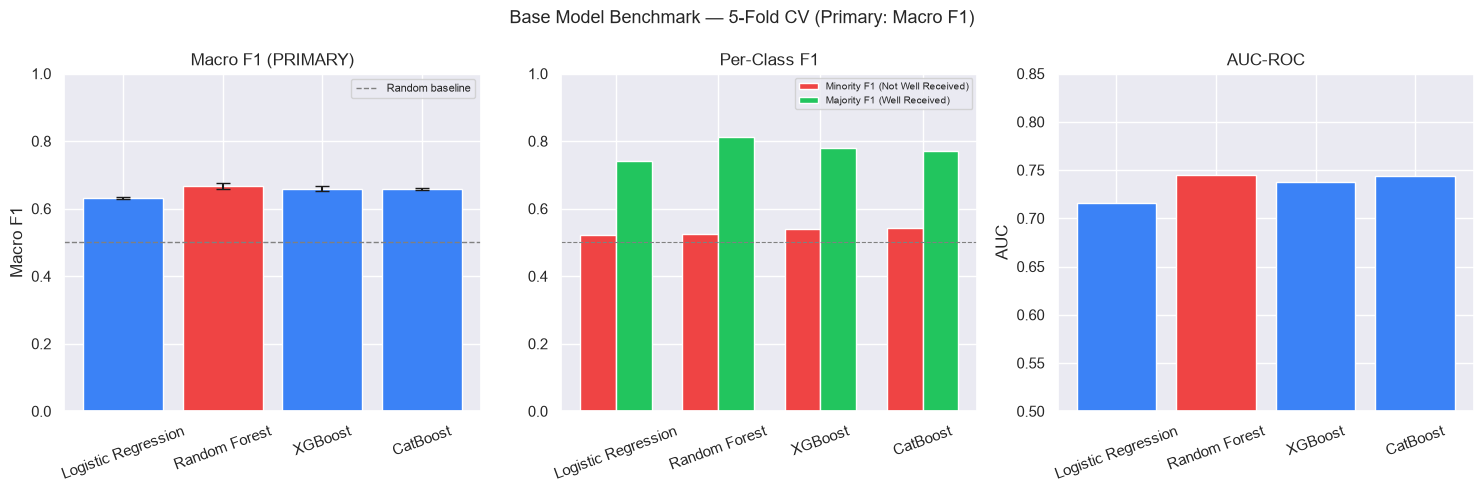

Saved: 03_benchmark_comparison.png


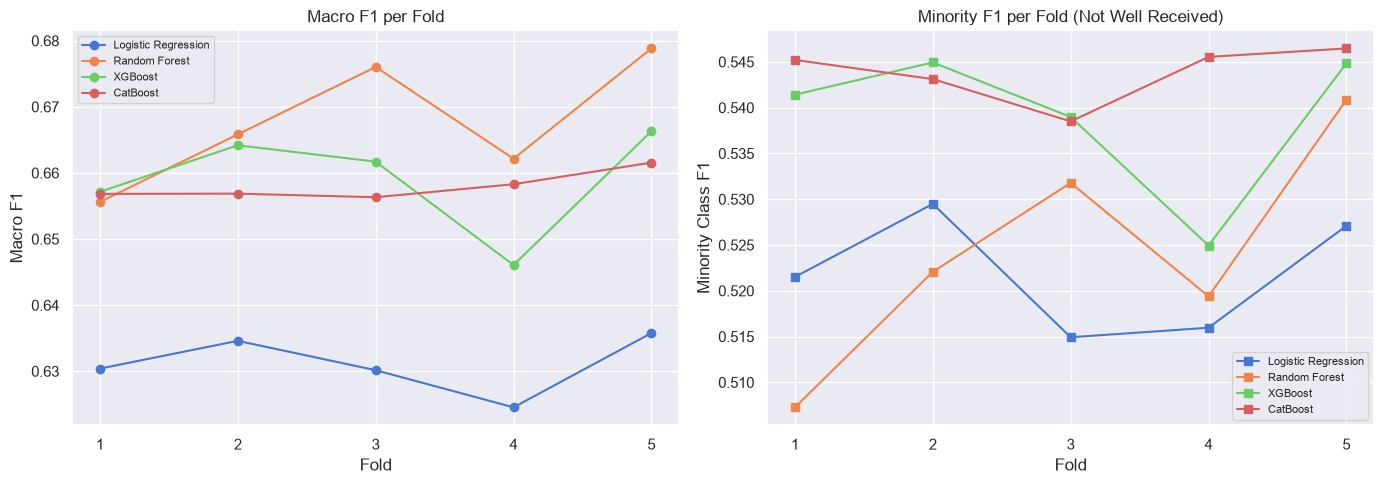

Saved: 03_fold_stability.png


In [8]:
names        = list(cv_results.keys())
macro_f1s    = [cv_results[n]['f1_macro_mean']   for n in names]
macro_f1_std = [cv_results[n]['f1_macro_std']    for n in names]
minor_f1s    = [cv_results[n]['f1_minority_mean'] for n in names]
major_f1s    = [cv_results[n]['f1_majority_mean'] for n in names]
aucs         = [cv_results[n]['auc_mean']         for n in names]
colors       = ['#ef4444' if n == best_name else '#3b82f6' for n in names]

# ── Chart 1: Macro F1 + per-class F1 + AUC ───────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.suptitle('Base Model Benchmark — 5-Fold CV (Primary: Macro F1)', fontsize=13)

# Macro F1 with error bars
axes[0].bar(names, macro_f1s, yerr=macro_f1_std, color=colors, capsize=5, edgecolor='white')
axes[0].set_title('Macro F1 (PRIMARY)')
axes[0].set_ylabel('Macro F1')
axes[0].set_ylim(0, 1)
axes[0].tick_params(axis='x', rotation=20)
axes[0].axhline(0.5, color='gray', linestyle='--', linewidth=1, label='Random baseline')
axes[0].legend(fontsize=8)

# Per-class F1 side by side
x = np.arange(len(names))
w = 0.35
axes[1].bar(x - w/2, minor_f1s, w, label='Minority F1 (Not Well Received)',
            color='#ef4444', edgecolor='white')
axes[1].bar(x + w/2, major_f1s, w, label='Majority F1 (Well Received)',
            color='#22c55e', edgecolor='white')
axes[1].set_title('Per-Class F1')
axes[1].set_xticks(x)
axes[1].set_xticklabels(names, rotation=20)
axes[1].set_ylim(0, 1)
axes[1].legend(fontsize=7)
axes[1].axhline(0.5, color='gray', linestyle='--', linewidth=0.8)

# AUC-ROC
axes[2].bar(names, aucs, color=colors, edgecolor='white')
axes[2].set_title('AUC-ROC')
axes[2].set_ylabel('AUC')
axes[2].set_ylim(0.5, 0.85)
axes[2].tick_params(axis='x', rotation=20)

plt.tight_layout()
plt.savefig(PROJECT_ROOT / 'outputs' / 'figures' / '03_benchmark_comparison.png',
            dpi=150, bbox_inches='tight')
plt.show()
print('Saved: 03_benchmark_comparison.png')

# ── Chart 2: Per-fold stability ───────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for name, r in cv_results.items():
    folds = range(1, CV_FOLDS + 1)
    axes[0].plot(folds, r['fold_macro_f1s'], marker='o', label=name, linewidth=1.5)
axes[0].set_xlabel('Fold')
axes[0].set_ylabel('Macro F1')
axes[0].set_title('Macro F1 per Fold')
axes[0].legend(fontsize=8)
axes[0].set_xticks(range(1, CV_FOLDS + 1))

for name, r in cv_results.items():
    axes[1].plot(range(1, CV_FOLDS + 1), r['fold_minor_f1s'],
                 marker='s', label=name, linewidth=1.5)
axes[1].set_xlabel('Fold')
axes[1].set_ylabel('Minority Class F1')
axes[1].set_title('Minority F1 per Fold (Not Well Received)')
axes[1].legend(fontsize=8)
axes[1].set_xticks(range(1, CV_FOLDS + 1))

plt.tight_layout()
plt.savefig(PROJECT_ROOT / 'outputs' / 'figures' / '03_fold_stability.png',
            dpi=150, bbox_inches='tight')
plt.show()
print('Saved: 03_fold_stability.png')


## 8. Winner Selection & Final Evaluation on Test Set

The best classifier is retrained on the **full training set** and evaluated
on the **held-out test set** for a final unbiased performance estimate.

This is the only time the test set is used in this notebook.


Tuned model (CB tuned) beats baseline (Random Forest):
  CB tuned Macro F1=0.6695  vs  Random Forest Macro F1=0.6677
Refitting CB tuned on full training set...
Done.

Tuning decision threshold on cross-validated training predictions (test set stays untouched until final evaluation)...
  Default  threshold (0.50): CV Macro F1=0.6695  CV Minority F1=0.5313
  Optimal threshold (0.50): CV Macro F1=0.6695  CV Minority F1=0.5313


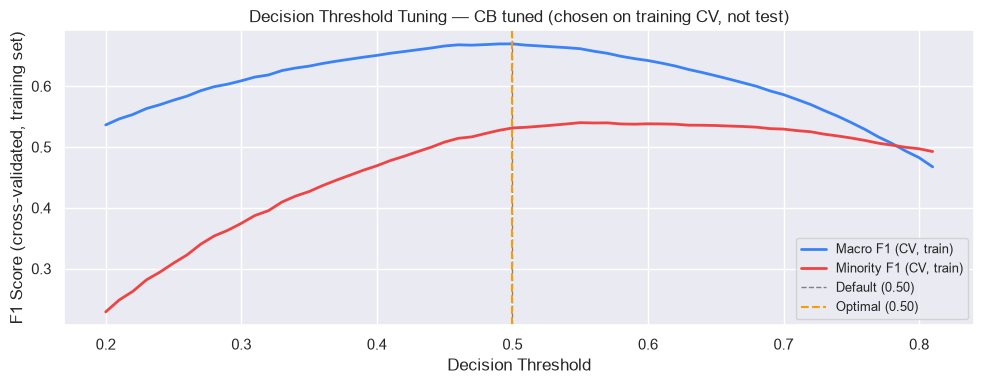

Saved: 03_threshold_tuning.png

=== TEST SET RESULTS — CB tuned (threshold chosen on training CV) ===
  Metric                       Default (0.50)   Optimal (0.50)
  --------------------------------------------------------------
  Macro F1 (PRIMARY)                   0.6603           0.6603
  Minority F1 (Not Well Rec.)          0.5214           0.5214
  AUC-ROC                              0.7383           0.7383
  Accuracy                             0.7172           0.7172

Classification report (optimal threshold = 0.50):
                   precision    recall  f1-score   support

Not Well Received       0.50      0.55      0.52      1151
    Well Received       0.81      0.78      0.80      2926

         accuracy                           0.72      4077
        macro avg       0.66      0.67      0.66      4077
     weighted avg       0.73      0.72      0.72      4077



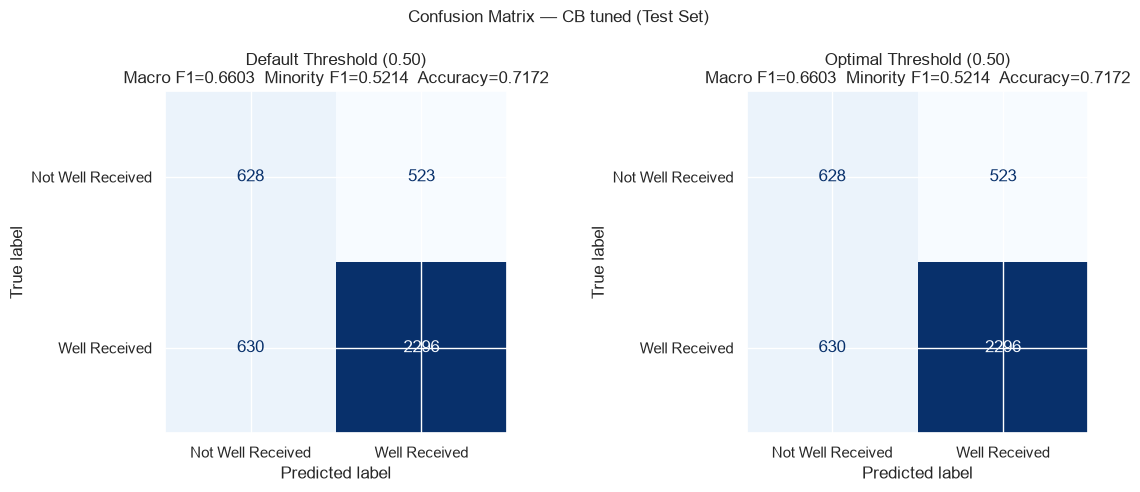

Saved: 03_confusion_matrix.png


In [9]:
# ── Select the best model — tuned or baseline ─────────────────────────────────
baseline_best_macro = cv_results[best_name]['f1_macro_mean']

# Map a tuning-stage label (e.g. "CB tuned", "RF baseline") back to the actual
# classifier name used as a key in cv_results — needed because WINNER_NAME may
# come from `all_results` (section 6b) which uses different label strings.
_LABEL_TO_BASE_NAME = {
    'RF baseline': 'Random Forest', 'CB baseline': 'CatBoost',
    'RF tuned':    'Random Forest', 'CB tuned':    'CatBoost',
}

if TUNED_BEST_MACRO > baseline_best_macro:
    print(f'Tuned model ({TUNED_BEST_LABEL}) beats baseline ({best_name}):')
    print(f'  {TUNED_BEST_LABEL} Macro F1={TUNED_BEST_MACRO:.4f}  vs  '
          f'{best_name} Macro F1={baseline_best_macro:.4f}')
    WINNER_NAME      = TUNED_BEST_LABEL
    WINNER_BASE_NAME = _LABEL_TO_BASE_NAME.get(TUNED_BEST_LABEL, TUNED_BEST_LABEL)
    WINNER_STRATEGY  = best_strategy
    final_clf        = TUNED_ESTIMATORS[TUNED_BEST_LABEL]
    # Already fitted during tuning — refit on full training set
    print(f'Refitting {WINNER_NAME} on full training set...')
    final_clf.fit(X_train, y_train)
else:
    print(f'Baseline {best_name} holds — tuning did not improve macro F1.')
    print(f'  Baseline Macro F1={baseline_best_macro:.4f}  Tuned best={TUNED_BEST_MACRO:.4f}')
    WINNER_NAME      = best_name
    WINNER_BASE_NAME = best_name
    WINNER_STRATEGY  = best_strategy
    if WINNER_STRATEGY == 'no_weighting':
        if WINNER_NAME == 'CatBoost':
            final_clf = CatBoostClassifier(iterations=300, learning_rate=0.05,
                                            depth=6, random_seed=RANDOM_STATE, verbose=0)
        elif WINNER_NAME == 'XGBoost':
            final_clf = XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=6,
                                       eval_metric='logloss', use_label_encoder=False,
                                       random_state=RANDOM_STATE, n_jobs=-1, verbosity=0)
        elif WINNER_NAME == 'Random Forest':
            final_clf = RandomForestClassifier(n_estimators=300, max_depth=None,
                                                min_samples_leaf=2,
                                                random_state=RANDOM_STATE, n_jobs=-1)
        else:
            final_clf = Pipeline([('scaler', StandardScaler()),
                                   ('clf', LogisticRegression(max_iter=1000,
                                    random_state=RANDOM_STATE, n_jobs=-1))])
    elif WINNER_STRATEGY == 'SMOTE' and SMOTE_AVAILABLE:
        final_clf = ImbPipeline([('smote', SMOTE(random_state=RANDOM_STATE)),
                                  ('clf', CLASSIFIERS[WINNER_NAME])])
    else:
        final_clf = CLASSIFIERS[WINNER_NAME]
    print(f'Fitting {WINNER_NAME} on full training set ({X_train.shape[0]:,} games)...')
    final_clf.fit(X_train, y_train)

print('Done.')

# ── Threshold tuning — on cross-validated TRAINING predictions only ───────────
# Previously this swept thresholds against the held-out test set itself, then
# reported "optimal" test performance using that same threshold on that same
# test set — using the test set twice. Fixed: get out-of-fold probabilities on
# the training set via cross_val_predict, pick the threshold there, and apply
# the frozen threshold to the test set exactly once, below.
from sklearn.base import clone
from sklearn.model_selection import cross_val_predict

print()
print('Tuning decision threshold on cross-validated training predictions '
      '(test set stays untouched until final evaluation)...')
cv_probs = cross_val_predict(
    clone(final_clf), X_train, y_train,
    cv=cv, method='predict_proba', n_jobs=1
)[:, 1]

thresholds  = np.arange(0.20, 0.81, 0.01)
macro_f1s_t = []
minor_f1s_t = []

for t in thresholds:
    y_pred_t = (cv_probs >= t).astype(int)
    macro_f1s_t.append(f1_score(y_train, y_pred_t, average='macro', zero_division=0))
    minor_f1s_t.append(f1_score(y_train, y_pred_t, pos_label=0, zero_division=0))

best_t_idx     = int(np.argmax(macro_f1s_t))
BEST_THRESHOLD = float(thresholds[best_t_idx])
default_idx    = int(np.argmin(np.abs(thresholds - 0.50)))

print(f'  Default  threshold (0.50): CV Macro F1={macro_f1s_t[default_idx]:.4f}  '
      f'CV Minority F1={minor_f1s_t[default_idx]:.4f}')
print(f'  Optimal threshold ({BEST_THRESHOLD:.2f}): CV Macro F1={macro_f1s_t[best_t_idx]:.4f}  '
      f'CV Minority F1={minor_f1s_t[best_t_idx]:.4f}')

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(thresholds, macro_f1s_t, label='Macro F1 (CV, train)',    color='#3b82f6', linewidth=2)
ax.plot(thresholds, minor_f1s_t, label='Minority F1 (CV, train)', color='#ef4444', linewidth=2)
ax.axvline(0.50,           color='gray',    linestyle='--', linewidth=1, label='Default (0.50)')
ax.axvline(BEST_THRESHOLD, color='#f59e0b', linestyle='--', linewidth=1.5,
           label=f'Optimal ({BEST_THRESHOLD:.2f})')
ax.set_xlabel('Decision Threshold')
ax.set_ylabel('F1 Score (cross-validated, training set)')
ax.set_title(f'Decision Threshold Tuning — {WINNER_NAME} (chosen on training CV, not test)')
ax.legend(fontsize=9)
plt.tight_layout()
plt.savefig(PROJECT_ROOT / 'outputs' / 'figures' / '03_threshold_tuning.png',
            dpi=150, bbox_inches='tight')
plt.show()
print('Saved: 03_threshold_tuning.png')

# ── Final test evaluation — test set used exactly once, here ──────────────────
y_prob = final_clf.predict_proba(X_test)[:, 1]
y_pred_default = (y_prob >= 0.50).astype(int)
y_pred_optimal = (y_prob >= BEST_THRESHOLD).astype(int)

test_macro_default = f1_score(y_test, y_pred_default, average='macro')
test_macro_optimal = f1_score(y_test, y_pred_optimal, average='macro')
test_minor_default = f1_score(y_test, y_pred_default, pos_label=0)
test_minor_optimal = f1_score(y_test, y_pred_optimal, pos_label=0)
test_auc           = roc_auc_score(y_test, y_prob)
test_acc_default   = accuracy_score(y_test, y_pred_default)
test_acc_optimal   = accuracy_score(y_test, y_pred_optimal)

print()
print(f'=== TEST SET RESULTS — {WINNER_NAME} (threshold chosen on training CV) ===')
print(f'  {"Metric":<28} {"Default (0.50)":>14} {"Optimal ({:.2f})".format(BEST_THRESHOLD):>16}')
print('  ' + '-' * 62)
print(f'  {"Macro F1 (PRIMARY)":<28} {test_macro_default:>14.4f} {test_macro_optimal:>16.4f}')
print(f'  {"Minority F1 (Not Well Rec.)":<28} {test_minor_default:>14.4f} {test_minor_optimal:>16.4f}')
print(f'  {"AUC-ROC":<28} {test_auc:>14.4f} {test_auc:>16.4f}')
print(f'  {"Accuracy":<28} {test_acc_default:>14.4f} {test_acc_optimal:>16.4f}')
print()
print(f'Classification report (optimal threshold = {BEST_THRESHOLD:.2f}):')
print(classification_report(y_test, y_pred_optimal,
                             target_names=['Not Well Received', 'Well Received']))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (y_pred, title) in zip(axes, [
    (y_pred_default, 'Default Threshold (0.50)'),
    (y_pred_optimal, f'Optimal Threshold ({BEST_THRESHOLD:.2f})')
]):
    cm   = confusion_matrix(y_test, y_pred)
    disp = ConfusionMatrixDisplay(cm, display_labels=['Not Well Received', 'Well Received'])
    disp.plot(ax=ax, colorbar=False, cmap='Blues')
    mf1 = f1_score(y_test, y_pred, average='macro')
    mnf = f1_score(y_test, y_pred, pos_label=0)
    acc = accuracy_score(y_test, y_pred)
    ax.set_title(f'{title}\nMacro F1={mf1:.4f}  Minority F1={mnf:.4f}  Accuracy={acc:.4f}')

plt.suptitle(f'Confusion Matrix — {WINNER_NAME} (Test Set)', fontsize=12)
plt.tight_layout()
plt.savefig(PROJECT_ROOT / 'outputs' / 'figures' / '03_confusion_matrix.png',
            dpi=150, bbox_inches='tight')
plt.show()
print('Saved: 03_confusion_matrix.png')


## 9. Save Benchmark Table

In [10]:
rows = []
for name, r in cv_results.items():
    is_win = (name == WINNER_BASE_NAME)   # FIX: was `name == WINNER_NAME`, which never
                                            # matched when a tuned model won (WINNER_NAME
                                            # held labels like "CB tuned"). See revision note.
    rows.append({
        'classifier':             name,
        'cv_macro_f1_mean':       round(r['f1_macro_mean'], 4),
        'cv_macro_f1_std':        round(r['f1_macro_std'], 4),
        'cv_minority_f1_mean':    round(r['f1_minority_mean'], 4),
        'cv_majority_f1_mean':    round(r['f1_majority_mean'], 4),
        'cv_auc_mean':            round(r['auc_mean'], 4),
        'cv_auc_std':             round(r['auc_std'], 4),
        'train_time_sec':         round(r['time_sec'], 1),
        'is_winner':              is_win,
        'winner_label':           WINNER_NAME if is_win else None,  # e.g. "CB tuned"
        'imbalance_strategy':     WINNER_STRATEGY if is_win else 'class_weight',
        'test_macro_f1_default':  round(test_macro_default, 4) if is_win else None,
        'test_macro_f1_optimal':  round(test_macro_optimal, 4) if is_win else None,
        'test_minority_f1':       round(test_minor_optimal, 4) if is_win else None,
        'test_auc':               round(test_auc, 4)           if is_win else None,
        'cv_accuracy_mean':        round(r['accuracy_mean'], 4),
        'cv_accuracy_std':         round(r['accuracy_std'], 4),
        'test_accuracy_default':   round(test_acc_default, 4)  if is_win else None,
        'test_accuracy_optimal':   round(test_acc_optimal, 4)  if is_win else None,
        'optimal_threshold':      round(BEST_THRESHOLD, 2)     if is_win else None,
    })

benchmark_df = pd.DataFrame(rows)

# Guard: exactly one row must be the winner, or the mapping/fix above is broken
n_winners = benchmark_df['is_winner'].sum()
assert n_winners == 1, (
    f'Expected exactly 1 winning row, got {n_winners} — WINNER_BASE_NAME '
    f'("{WINNER_BASE_NAME}") did not match any cv_results key {list(cv_results.keys())}'
)

benchmark_df.to_csv(RESULTS_DIR / 'benchmark_table.csv', index=False)
print(f'Saved: {RESULTS_DIR / "benchmark_table.csv"}')
print(f'✓ Winner correctly recorded: {WINNER_NAME} (base classifier: {WINNER_BASE_NAME})')
print()
print('=== BENCHMARK TABLE (sorted by Macro F1) ===')
print(benchmark_df.sort_values('cv_macro_f1_mean', ascending=False).to_string(index=False))


Saved: C:\Users\3214h\Documents\fyp-steam-reception\outputs\results\benchmark_table.csv
✓ Winner correctly recorded: CB tuned (base classifier: CatBoost)

=== BENCHMARK TABLE (sorted by Macro F1) ===
         classifier  cv_macro_f1_mean  cv_macro_f1_std  cv_minority_f1_mean  cv_majority_f1_mean  cv_auc_mean  cv_auc_std  train_time_sec  is_winner winner_label imbalance_strategy  test_macro_f1_default  test_macro_f1_optimal  test_minority_f1  test_auc  cv_accuracy_mean  cv_accuracy_std  test_accuracy_default  test_accuracy_optimal  optimal_threshold
      Random Forest            0.6677           0.0086               0.5243               0.8111       0.7444      0.0054          8.8000      False          NaN       class_weight                    NaN                    NaN               NaN       NaN            0.7296           0.0083                    NaN                    NaN                NaN
            XGBoost            0.6591           0.0072               0.5390               

## 9b. Export Winning Hyperparameters

Notebook 04 trains specialist Models A-D using "the tuned hyperparameters from
notebook 03" — but if that's just a hand-typed comment in NB04, it can silently
drift from what this notebook actually found (exactly the kind of unverified,
copy-typed provenance this rewrite is meant to eliminate). Instead, export the
winning classifier's actual parameters here as a JSON file, so NB04 **loads**
this file rather than retyping numbers by hand.


In [11]:
import json as _json

def _extract_underlying_classifier(clf):
    """Unwrap a Pipeline/ImbPipeline to get the actual classifier step."""
    if hasattr(clf, 'named_steps'):
        return clf.named_steps.get('clf', clf)
    return clf

def _json_safe(value):
    """Coerce a get_params() value into something JSON can serialise."""
    if value is None or isinstance(value, (bool, int, float, str)):
        return value
    if isinstance(value, dict):
        return {str(k): _json_safe(v) for k, v in value.items()}
    if isinstance(value, (list, tuple)):
        return [_json_safe(v) for v in value]
    return str(value)

winner_clf  = _extract_underlying_classifier(final_clf)
winner_type = type(winner_clf).__name__

# Only keep params relevant to reproducing the model — get_params() on CatBoost/
# XGBoost/sklearn models includes a lot of internal defaults we don't need to track.
_KEY_PARAMS_BY_TYPE = {
    'CatBoostClassifier':      ['iterations', 'learning_rate', 'depth',
                                 'l2_leaf_reg', 'scale_pos_weight', 'random_seed'],
    'XGBClassifier':           ['n_estimators', 'learning_rate', 'max_depth',
                                 'scale_pos_weight', 'random_state'],
    'RandomForestClassifier':  ['n_estimators', 'max_depth', 'min_samples_leaf',
                                 'max_features', 'class_weight', 'random_state'],
    'LogisticRegression':      ['class_weight', 'max_iter', 'random_state'],
}

all_params = winner_clf.get_params()
key_names  = _KEY_PARAMS_BY_TYPE.get(winner_type, list(all_params.keys()))
key_params = {k: _json_safe(all_params.get(k)) for k in key_names if k in all_params}

hyperparam_export = {
    'winner_label':        WINNER_NAME,          # e.g. "CB tuned"
    'winner_base_name':    WINNER_BASE_NAME,      # e.g. "CatBoost" — matches cv_results keys
    'classifier_type':     winner_type,           # e.g. "CatBoostClassifier"
    'imbalance_strategy':  WINNER_STRATEGY,
    'decision_threshold':  BEST_THRESHOLD,
    'hyperparameters':     key_params,
    'cv_macro_f1':         round(TUNED_BEST_MACRO, 4),
    'test_macro_f1_optimal': round(test_macro_optimal, 4),
    'source_notebook':     '03_base_model_benchmark',
}

_hp_path = RESULTS_DIR / '03_winner_hyperparameters.json'
with open(_hp_path, 'w') as f:
    _json.dump(hyperparam_export, f, indent=2)

print(f'Saved: {_hp_path}')
print()
print('=== EXPORTED WINNING HYPERPARAMETERS ===')
print(f'  Classifier : {winner_type}  ({WINNER_NAME})')
for k, v in key_params.items():
    print(f'  {k:<20}: {v}')
print(f'  decision_threshold  : {BEST_THRESHOLD}')


Saved: C:\Users\3214h\Documents\fyp-steam-reception\outputs\results\03_winner_hyperparameters.json

=== EXPORTED WINNING HYPERPARAMETERS ===
  Classifier : CatBoostClassifier  (CB tuned)
  iterations          : 1000
  learning_rate       : 0.1
  depth               : 4
  l2_leaf_reg         : 5
  scale_pos_weight    : 0.5
  random_seed         : 42
  decision_threshold  : 0.5000000000000002


## 10. Summary

In [12]:
print('=' * 65)
print('NOTEBOOK 03 — BASE MODEL BENCHMARK SUMMARY')
print('=' * 65)

print(f'\nDATASET')
print(f'  Total games    : {len(df):,}')
print(f'  Features (T4)  : {len(T4_FEATURES)}')
print(f'  Train set      : {X_train.shape[0]:,} games')
print(f'  Test set       : {X_test.shape[0]:,} games')
print(f'  CV strategy    : {CV_FOLDS}-fold stratified')
print(f'  Primary metric : Macro F1 (equal weight to both classes)')

print(f'\nBASELINE CLASSIFIER RANKING (by CV Macro F1):')
ranked = sorted(cv_results.items(), key=lambda x: x[1]['f1_macro_mean'], reverse=True)
for rank, (name, r) in enumerate(ranked, 1):
    print(f'  {rank}. {name:<25} Macro F1={r["f1_macro_mean"]:.4f} ± {r["f1_macro_std"]:.4f}  '
          f'Minority F1={r["f1_minority_mean"]:.4f}')

print(f'\nHYPERPARAMETER TUNING RESULTS:')
print(f'  RF tuned   : Macro F1={rf_tuned_macro:.4f}  Minority F1={rf_tuned_minor:.4f}')
print(f'  CB tuned   : Macro F1={cb_tuned_macro:.4f}  Minority F1={cb_tuned_minor:.4f}')

print(f'\nFINAL WINNER: {WINNER_NAME}')
print(f'  Imbalance strategy      : {WINNER_STRATEGY}')
print(f'  CV Macro F1             : {TUNED_BEST_MACRO:.4f}  (baseline best was '
      f'{cv_results[best_name]["f1_macro_mean"]:.4f})')
print(f'  Test Macro F1 (optimal) : {test_macro_optimal:.4f}  (threshold={BEST_THRESHOLD:.2f})')
print(f'  Test Minority F1        : {test_minor_optimal:.4f}')
print(f'  Test Accuracy (optimal) : {test_acc_optimal:.4f}')
print(f'  Test AUC-ROC            : {test_auc:.4f}')
print(f'  Optimal threshold       : {BEST_THRESHOLD:.2f}')

print(f'\nNOTE: Further improvement beyond ~0.72 macro F1 requires SBERT text')
print(f'  features (notebook 05). The structured features alone have AUC=0.74,')
print(f'  which limits the theoretical macro F1 ceiling at this feature set.')

print(f'\nNEXT STEP: Notebook 04 — Specialist Models + Router')
print(f'  Classifier      : {WINNER_NAME}')
print(f'  Imbalance       : {WINNER_STRATEGY}')
print(f'  Primary metric  : Macro F1')
print(f'  Threshold       : {BEST_THRESHOLD:.2f}')
print(f'  Train Models A (T1), B (T2), C (T3), D (T4)')
print(f'  Implement confidence-based router')
print('=' * 65)


NOTEBOOK 03 — BASE MODEL BENCHMARK SUMMARY

DATASET
  Total games    : 20,383
  Features (T4)  : 53
  Train set      : 16,306 games
  Test set       : 4,077 games
  CV strategy    : 5-fold stratified
  Primary metric : Macro F1 (equal weight to both classes)

BASELINE CLASSIFIER RANKING (by CV Macro F1):
  1. Random Forest             Macro F1=0.6677 ± 0.0086  Minority F1=0.5243
  2. XGBoost                   Macro F1=0.6591 ± 0.0072  Minority F1=0.5390
  3. CatBoost                  Macro F1=0.6580 ± 0.0019  Minority F1=0.5438
  4. Logistic Regression       Macro F1=0.6311 ± 0.0040  Minority F1=0.5218

HYPERPARAMETER TUNING RESULTS:
  RF tuned   : Macro F1=0.6644  Minority F1=0.5336
  CB tuned   : Macro F1=0.6695  Minority F1=0.5313

FINAL WINNER: CB tuned
  Imbalance strategy      : class_weight
  CV Macro F1             : 0.6695  (baseline best was 0.6677)
  Test Macro F1 (optimal) : 0.6603  (threshold=0.50)
  Test Minority F1        : 0.5214
  Test Accuracy (optimal) : 0.7172
  Tes